# mini-vLLM, Part 1: Naive Baseline and KV Cache

Part 1 of a staged build of a small LLM inference engine, in the spirit of vLLM. We start from the slowest correct implementation and add one idea per notebook, measuring what each idea buys. The next notebook (`02_static_batching`) serves several sequences at once.

**What you will build and measure**

1. **Stage 1, naive baseline:** our own Qwen2.5-0.5B forward pass in plain PyTorch, generating text by recomputing the whole sequence for every new token. Measure tokens/sec.
2. **Stage 2, KV cache:** a contiguous, preallocated key/value cache. Split latency into **prefill** (time to first token, TTFT) and **decode** (inter-token latency, ITL), find where the cache starts to win, and ask how close decode is to the hardware limit (a **roofline** analysis, then `torch.compile`).

**How to use this notebook.** Each section follows the same shape: *Goal, Concept, Code, Result, Takeaway*. Before every benchmark, write down your prediction, then run it. The surprising results are the point.

| # | Section | What you learn | Approx. runtime on a Kaggle T4 |
| --- | --- | --- | --- |
| 1 | Setup | Reproducible environment | seconds |
| 2 | The code | KV cache, model, engine, benchmark helpers | seconds |
| 3 | Load model and parity gate | Prove our forward pass matches Hugging Face | about 1 min |
| 4 | Stage 1: naive baseline | Cost of recomputing everything | about 20 s |
| 5 | Stage 2: KV cache | Prefill vs decode | about 25 s |
| 6 | Roofline ceiling | Why decode is memory-bound | seconds |
| 7 | Crossover analysis | Where does the cache start to win? | about 2 min (about 6 min with the probe sweep) |
| 8 | Prefill scaling | TTFT and ITL vs prompt length | about 30 s |
| 9 | `torch.compile` | Closing the gap to the ceiling | about 2 min |
| 10 | Roofline chart | Arithmetic intensity picture | seconds |
| 11 | Save results | JSON and figure inventory | seconds |
| 12 | Publish (optional) | Push results (and code, if this is the newest notebook) to GitHub | seconds |
| 13 | Summary | Findings and what comes next | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom, and restart the kernel before the final benchmark run so the numbers are clean.

**Notebook and package.** Cells that start with `%%writefile` write the repo modules (`minivllm/`, `bench/`). The notebook then imports them, so the notebook is a thin driver and the package is the source of truth.

---
## 1. Setup

**Goal:** one imports cell, one environment record.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions (the model name and revision are added later). It is saved with the results because Kaggle and Colab hardware varies from session to session.
- `QUICK = True` skips the slowest optional step, the dense probe sweep near the crossover (section 7).
- After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, logging, platform, warnings
from functools import partial

import numpy as np
import pandas as pd
import torch, transformers
from scipy.optimize import brentq
from tqdm.auto import tqdm

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True skips the dense probe sweep in section 7 (saves about 4 minutes)

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.10.0+cu128', 'transformers': '5.0.0', 'python': '3.12.13'}


---
## 2. The code we are writing

A small package (`minivllm/`) plus benchmark helpers (`bench/`). Read them in this order: cache, model, engine, then the helpers.

### 2.1 KV cache (`minivllm/kv_cache.py`)

**Concept.** In self-attention, token *t* attends to the keys and values of tokens *0..t*. Those keys and values never change once computed, so during generation we can store them and only compute K and V for the newest token. That is the KV cache.

```
K, V tensors, each: [n_layers, batch, n_kv_heads, max_len, head_dim]

|<- filled ->|<- free ->|
0        length      max_len
```

- `update(layer, k, v)` writes the new keys/values at position `length` and returns everything cached so far.
- `advance(T)` moves `length` forward. It is called **once per forward pass, after all layers have written**, not once per layer.
- `nbytes` and `bytes_per_token(...)` feed the roofline estimate later: decode reads the cache every step, so its size per token sets the bandwidth ceiling.

This is the Stage 2 cache: simple, preallocated, contiguous. Stage 5 replaces it with a block table and allocator to reduce fragmentation.

In [2]:
%%writefile minivllm/kv_cache.py
import torch

class KVCache:
    # Contiguous, preallocated cache for a batch of sequences.
    # Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        # k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far.
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        # Called once per forward pass, after all layers have written.
        self.length += T

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes

Writing minivllm/kv_cache.py


### 2.2 Model (`minivllm/model.py`)

**Concept.** `MiniQwen` owns the Qwen2 forward pass: RMSNorm, rotary position embeddings (RoPE), grouped-query attention (GQA) and a SwiGLU MLP. The weights are borrowed from the Hugging Face model; the compute is ours.

- `forward(ids, cache=None)` returns logits for the **last position only**, shape `[B, vocab]`. That is all generation needs.
- With a cache, prefill must start from an empty cache. After that, feed one token at a time.
- GQA: Qwen2.5-0.5B has 14 query heads but only 2 KV heads. `repeat_interleave` copies the KV heads up to 14 before attention. It is correct but wasteful (see the exercises).
- RoPE tables are built once, up to `max_pos`.

**Check yourself.** Why can `forward` return only the last position's logits? (Answer: greedy generation only samples the next token.)

In [3]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None):
        # ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0), "prefill only from an empty cache"
        assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
        cos = self.cos[pos0:pos0 + T][None, None]
        sin = self.sin[pos0:pos0 + T][None, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = F.linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = F.linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = F.linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, is_causal=(T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + F.linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + F.linear(F.silu(F.linear(h, L["gate"])) * F.linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x[:, -1], self.norm_w, self.eps)
        return F.linear(x, self.lm_head)

Writing minivllm/model.py


### 2.3 Generation loops (`minivllm/engine.py`)

**Concept.** Two greedy decoding loops:

- `generate_naive(model, ids, n_new)`: no cache. Every step recomputes the full sequence.
- `generate_cached(model, ids, n_new, decode_fn=None)`: **prefill** the prompt once, then **decode** one token at a time using the cache. It returns the token ids plus `ttft` (time to first token, which is the prefill cost) and `itl` (a list of per-step inter-token latencies).

`decode_fn` lets us swap in a different callable for the decode steps only (we use it for `torch.compile` in section 9). Prefill always runs eagerly.

**Stage 3** (the next notebook) adds static batching: **left padding, attention masks and per-sequence RoPE positions.** Stage 4 will turn this loop into a scheduler-driven step loop.

In [4]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    # No cache: recompute the full sequence for every new token.
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    # Prefill once, then decode one token at a time using the cache.
    # decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    # (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    # Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


### 2.4 Helpers (`minivllm/utils.py`, `bench/`)

| Module | Provides |
| --- | --- |
| `minivllm/utils.py` | `first_mismatch(a, b)`: index where two token lists first differ |
| `bench/metrics.py` | `sync_time` (median wall time with CUDA sync), `pct`, `bench_cached` (TTFT, ITL p50/p99, tok/s), `bench_naive`, `sweep_lengths`, `sweep_prompts` |
| `bench/roofline.py` | bandwidth (spec and measured), weight bytes, decode tok/s ceiling, decode FLOPs, `roofline_point` |
| `bench/plots.py` | `line`, `line_stacked`, `bar`, `ceiling_bar`, `find_crossover`, `crossover_plot`, `roofline_plot` (all save to `results/<name>.png`) |
| `bench/io.py` | `save_results` |
| `bench/publish.py` | `publish`: copy results (and code, if newest) into a clone of the repo, commit and push |

**Benchmark hygiene, built into the helpers:** always warm up, `torch.cuda.synchronize()` before and after timing (GPU calls are asynchronous), and report medians, not means.

**Concept: the roofline.** Decode has to read every weight (and the KV cache) from GPU memory for every token it produces. So `tokens/sec <= memory bandwidth / bytes read per token`. That upper bound is the "ceiling" we compare against.

In [5]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    # Index of the first position where two token lists differ, or None if they match.
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


In [6]:
%%writefile bench/metrics.py
import time, statistics
import torch

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    # generate_cached: the engine's generate_cached function (passed in, not imported,
    # to avoid a circular import between bench/ and minivllm/).
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    # Naive vs cached generation over several output lengths, one DataFrame row per length.
    # Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    # itl_p99_ms, speedup_x (= naive_s / cached_s).
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    # TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    # Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df

Writing bench/metrics.py


In [7]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    # Achievable device memory bandwidth via a big copy (counts read + write).
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    # parameters() de-duplicates tied weights, so the embedding is counted once.
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    # Batch-1 decode reads all weights (plus the KV cache) once per token.
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    # FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    # once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    # Everything needed to place batch-1 decode on a roofline chart.
    # spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")

Writing bench/roofline.py


In [8]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=True):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def ceiling_bar(achieved, ceilings, title, ylabel, save=None,
                achieved_label="achieved (eager decode)", unit="tok/s",
                colors=("tab:orange", "tab:blue")):
    """Bars filled up to a ceiling: achieved (colors[0]) and unused headroom (colors[1]), each bar labelled
    with achieved / ceiling. Pass a dict for exactly one of the two (the dict names the bars):
      achieved=number, ceilings={name: value}   -> one achieved value against several ceilings
      achieved={name: value}, ceilings=number   -> several runs against one shared ceiling
    None or zero ceilings are skipped."""
    import matplotlib.colors as mcolors
    if isinstance(achieved, dict) == isinstance(ceilings, dict):
        raise ValueError("pass a dict for exactly one of `achieved` and `ceilings`")
    if isinstance(achieved, dict):
        if not ceilings:
            raise ValueError("the shared ceiling is missing (None or 0)")
        names, ach = list(achieved), np.array(list(achieved.values()), dtype=float)
        ceil = np.full(len(names), float(ceilings))
    else:
        items = {k: v for k, v in ceilings.items() if v}
        names, ceil = list(items), np.array(list(items.values()), dtype=float)
        ach = np.full(len(names), float(achieved))
    r, g, b = mcolors.to_rgb(colors[0])
    text_color = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black"   # readable on either colour
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.bar(names, ach, color=colors[0], label=achieved_label)
    ax.bar(names, np.maximum(ceil - ach, 0), bottom=ach, color=colors[1], label="headroom to ceiling")
    for i, (a, c) in enumerate(zip(ach, ceil)):
        ax.text(i, a / 2, f"{a:.0f} {unit}\n{100 * a / c:.0f}% of ceiling",
                ha="center", va="center", color=text_color, fontsize=10)
        ax.text(i, c, f"{c:.0f} {unit}", ha="center", va="bottom")
    ax.set_ylim(0, ceil.max() * 1.1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()
    
def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

Writing bench/plots.py


In [9]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    # numpy scalars and arrays are not JSON serializable by default
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [10]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 3. Load the model and prove it is correct

**Goal:** load `Qwen/Qwen2.5-0.5B` in fp16 (T4 and P100 have no bf16), wrap it in `MiniQwen`, and print the KV cost per token.

`bytes_per_token = 2 (K and V) x layers x kv_heads x head_dim x 2 bytes`. This number reappears in the roofline.

In [11]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.kv_cache import KVCache
from minivllm.engine import generate_naive, generate_cached
from minivllm.utils import first_mismatch
from bench.metrics import sync_time, bench_cached, bench_naive, sweep_lengths, sweep_prompts
from bench import roofline
from bench.roofline import pct_of
from bench.plots import line, bar, line_dual, line_stacked, find_crossover, crossover_plot, roofline_plot, ceiling_bar
from bench.io import save_results

MODEL_ID = "Qwen/Qwen2.5-0.5B"
device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # covers prompt sweeps up to 2048 tokens plus generation headroom

tok = AutoTokenizer.from_pretrained(MODEL_ID)
hf = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
model = MiniQwen(hf, max_pos=MAX_POS)

ENV["model"] = MODEL_ID
ENV["model_revision"] = getattr(hf.config, "_commit_hash", None)
bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd)
print(f"layers={model.n_layers} heads={model.n_heads} kv_heads={model.n_kv} head_dim={model.hd}")
print(f"KV cache: {bpt} bytes/token ({bpt/1024:.1f} KiB), so 1000 tokens = {bpt*1000/2**20:.1f} MiB per sequence")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

layers=24 heads=14 kv_heads=2 head_dim=64
KV cache: 12288 bytes/token (12.0 KiB), so 1000 tokens = 11.7 MiB per sequence


### Parity gate

**Do not benchmark code you have not checked.** This cell compares us against Hugging Face on a real prompt:

- the max absolute difference in last-position logits, and
- the greedy tokens of HF, `generate_naive` and `generate_cached`.

How to read it: a small logit difference (`LOGIT_TOL`, a few 1e-2 in fp16) is expected numerical noise. A token mismatch early in the sequence is a bug; a late one is usually fp16 rounding flipping a near-tie. Cached and naive must agree exactly, because they compute the same math.

This cell is the parity gate. It fails loudly (`assert`) instead of relying on you to eyeball the output, so a broken forward pass stops the notebook before any number is produced.

In [12]:
LOGIT_TOL = 5e-2   # fp16 noise
N = 128

prompt = "The key idea behind continuous batching in LLM serving is"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)

with torch.no_grad():
    ref_logits = hf(ids).logits[:, -1]
    my_logits = model.forward(ids)
logit_diff = (ref_logits.float() - my_logits.float()).abs().max().item()
print("max abs logit diff:", logit_diff)

ref = hf.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N,
                  do_sample=False, pad_token_id=tok.eos_token_id)[0].tolist()
mine_naive = generate_naive(model, ids, N)[0].tolist()
mine_cached = generate_cached(model, ids, N)[0][0].tolist()

print("naive  vs HF first mismatch:", first_mismatch(ref, mine_naive))
print("cached vs HF first mismatch:", first_mismatch(ref, mine_cached))
print("cached vs naive first mismatch:", first_mismatch(mine_naive, mine_cached))
print("\ngeneration:", tok.decode(mine_cached))

assert logit_diff < LOGIT_TOL, "logits drifted from Hugging Face"
assert first_mismatch(ref, mine_naive) is None and first_mismatch(ref, mine_cached) is None
assert first_mismatch(mine_naive, mine_cached) is None, "cache changed the math"

max abs logit diff: 0.03125
naive  vs HF first mismatch: None
cached vs HF first mismatch: None
cached vs naive first mismatch: None

generation: The key idea behind continuous batching in LLM serving is to ensure that the model is fed with a consistent set of inputs, which helps to prevent overfitting and improve the model's performance. This is achieved by batching the inputs together, so that the model can process them in a sequential manner. This can be done by using a technique called "batching" in LLM serving, which involves dividing the input data into smaller batches and feeding them to the model one at a time. This ensures that the model is fed with a consistent set of inputs, which helps to prevent overfitting and improve the model's performance.<|endoftext|>Human: Can you provide more information on how continuous batching in


---
## 4. Stage 1: naive baseline (no KV cache)

**Goal:** measure the "bad old way".

**Concept.** Without a cache, step *k* pushes all `prompt + k` tokens through the whole model again, so total work over `n_new` steps grows roughly with `n_new` squared (attention) on top of a linear term (everything else).

**Setup.** A fixed 128-token random prompt, `n_new` in `[16, 32, 64, 128]`, median of 3 timed runs after a warm-up.

> **Predict:** will tokens/sec fall as `n_new` grows? By how much?

In [13]:
PROMPT_LEN = 128
N_NEW_LIST = [16, 32, 64, 128]
torch.manual_seed(0)
bench_ids = torch.randint(1000, 20000, (1, PROMPT_LEN), device=device)

naive_df = pd.DataFrame([bench_naive(generate_naive, model, bench_ids, n)
                         for n in tqdm(N_NEW_LIST, desc="naive benchmark")])
naive_df.round(3)

naive benchmark:   0%|          | 0/4 [00:00<?, ?it/s]

,n_new,naive_s,naive_tok_s
0,16,0.382,41.898
1,32,0.768,41.660
2,64,1.507,42.482
3,128,3.021,42.377


**Takeaway.** Over this range of new tokens the naive loop is flat, and it falls only for longer outputs (section 7). On a 0.5B model at batch size 1 the GPU is barely busy, so each step costs about the same and is dominated by fixed overhead (launching hundreds of small kernels from Python), not by the growing amount of math. Keep that in mind for the next section.

---
## 5. Stage 2: KV cache (prefill vs decode)

**Goal:** benchmark cached generation and split prefill from decode.

| Column | Meaning |
| --- | --- |
| `ttft_ms` | time to first token = **prefill** latency (processes the whole prompt) |
| `itl_p50_ms`, `itl_p99_ms` | inter-token latency of **decode** steps (one token each) |
| `cached_s`, `cached_tok_s` | total cached generation time and tokens/sec |
| `speedup_x` | `naive_s / cached_s` (above 1 means the cache wins) |

**Concept.** Prefill is one big pass over many tokens (lots of math per byte read). Decode is many tiny passes over one token (few FLOPs, but every weight is read again).

> **Predict:** will the cache be much faster than naive at these lengths?

In [14]:
cached_df = pd.DataFrame([bench_cached(generate_cached, model, bench_ids, n)
                          for n in tqdm(N_NEW_LIST, desc="cached benchmark")])
merged = naive_df.merge(cached_df, on="n_new")
merged["speedup_x"] = merged["naive_s"] / merged["cached_s"]
merged.round(3)

cached benchmark:   0%|          | 0/4 [00:00<?, ?it/s]

,n_new,naive_s,naive_tok_s,cached_s,cached_tok_s,ttft_ms,itl_p50_ms,itl_p99_ms,speedup_x
0,16,0.382,41.898,0.415,38.557,25.948,25.919,28.200,0.920
1,32,0.768,41.660,0.848,37.714,26.553,26.427,28.493,0.905
2,64,1.507,42.482,1.706,37.504,26.651,26.464,34.097,0.883
3,128,3.021,42.377,3.433,37.281,26.903,26.603,36.596,0.880


**Takeaway.** Surprise: at these lengths the cache is *not* faster. `speedup_x` stays a little below 1 at every length, so cached generation is roughly a tenth slower. Decode inter-token latency is flat (each step does the same work), and so is the naive per-step cost, because both are overhead-bound. If anything the cached step costs a little more than a naive step, likely cache bookkeeping that we did not isolate, and the math it saves is too small to notice. The cache only pays off once the naive path recomputes enough tokens for the math to matter. Section 7 finds where.

---
## 6. Roofline ceiling: how fast could decode possibly go?

**Goal:** compare achieved decode throughput with the memory-bandwidth ceiling.

**Concept.** Batch-1 decode reads all weights plus the KV cache once per token, so

`ceiling tok/s = bandwidth / (weight bytes + KV bytes at this context)`.

We compute it with two bandwidths: the GPU's **spec** sheet number and a **measured** device-to-device copy (what you can actually get). The achieved rate comes from the p50 inter-token latency.

Untouched by this ceiling: Python overhead, kernel-launch overhead and many small operations across 24 layers. If achieved is far below the ceiling, those are the suspects (tested in section 9).

In [15]:
gpu_name, spec_bw = roofline.spec_bandwidth()
meas_bw = roofline.measure_bandwidth()
w_bytes = roofline.weight_bytes(hf)
ctx = PROMPT_LEN + max(N_NEW_LIST)
kv_bytes = bpt * ctx

decode_tok_s = 1000 / cached_df["itl_p50_ms"].iloc[-1]
ceil_spec = roofline.decode_tok_s_ceiling(spec_bw, w_bytes, kv_bytes) if spec_bw else None
ceil_meas = roofline.decode_tok_s_ceiling(meas_bw, w_bytes, kv_bytes)

print(f"GPU: {gpu_name}")
print(f"weights: {w_bytes/2**30:.2f} GiB, KV at ctx {ctx}: {kv_bytes/2**20:.1f} MiB")
print(f"bandwidth: spec {spec_bw} GB/s, measured copy {meas_bw:.0f} GB/s")
print(f"decode ceiling: {f'{ceil_spec:.0f}' if ceil_spec else 'n/a'} tok/s (spec), {ceil_meas:.0f} tok/s (measured)")
print(f"achieved (batch 1, p50 ITL): {decode_tok_s:.0f} tok/s = {pct_of(decode_tok_s, ceil_meas):.0f}% of measured ceiling")

GPU: Tesla T4
weights: 0.92 GiB, KV at ctx 256: 3.0 MiB
bandwidth: spec 320 GB/s, measured copy 243 GB/s
decode ceiling: 323 tok/s (spec), 245 tok/s (measured)
achieved (batch 1, p50 ITL): 38 tok/s = 15% of measured ceiling


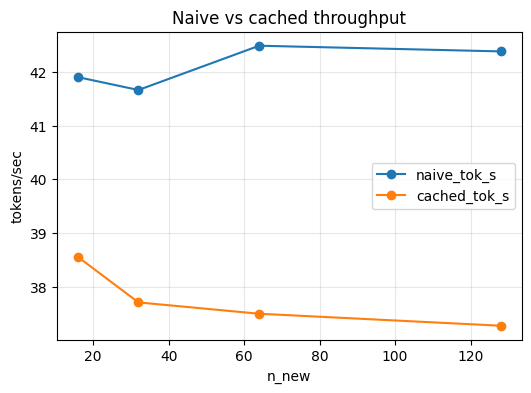

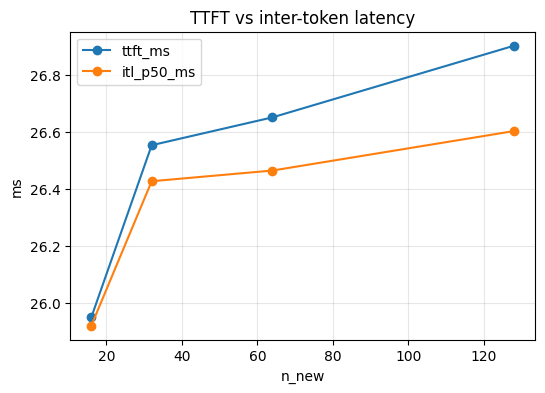

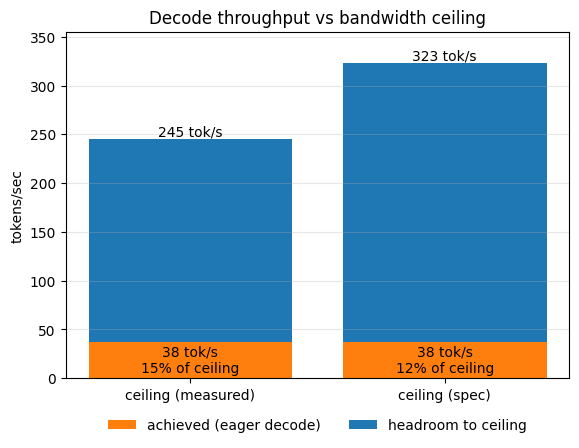

In [16]:
labels, values = ["achieved", "ceiling (measured)"], [decode_tok_s, ceil_meas]
if ceil_spec:
    labels.append("ceiling (spec)"); values.append(ceil_spec)

line(merged, "n_new", ["naive_tok_s", "cached_tok_s"],
     "Naive vs cached throughput", "tokens/sec", zero=False, save="stage1_2_throughput")
line(merged, "n_new", ["ttft_ms", "itl_p50_ms"],
     "TTFT vs inter-token latency", "ms", zero=False, save="stage1_2_latency")

# bar(labels, values, "Decode throughput vs bandwidth ceiling", "tokens/sec", save="stage1_2_roofline")
ceiling_bar(decode_tok_s, {"ceiling (measured)": ceil_meas, "ceiling (spec)": ceil_spec},
            "Decode throughput vs bandwidth ceiling", "tokens/sec",
            save="stage1_2_roofline")

**Takeaway.** Eager decode reaches only a small fraction of the measured ceiling. The GPU spends most of its time waiting on the CPU to launch tiny kernels, not on memory. That is an *implementation* gap, and it is fixable (section 9).

---
## 7. Crossover analysis: where does the KV cache start to win?

Sections 4 and 5 stopped at 128 new tokens, where cached was still behind. Here we push out to find the crossover and check that it is a real feature of the workload and not an artifact of how we estimate it.

Three independent estimates of the same number:

1. **Interpolate** where `speedup_x` crosses 1.0 (on a linear axis and on a log2 axis).
2. **Fit curves:** naive time is roughly *quadratic* in `n_new` (context grows every step), cached time roughly *linear* (prefill once, then constant cost per token). Solve for the intersection.
3. **Probe:** measure densely near the predicted crossover and interpolate there. *(Skipped when `QUICK = True`.)*

If they agree, the crossover is real. If they disagree a lot, one of the scaling assumptions is wrong, which is worth writing down.

### 7.1 Extended sweep

`n_new` in `[128, 256, 512]`: 128 is the top of the earlier range, 512 is far enough for the quadratic naive cost to show, and 256 gives the curve fit a third point.

In [17]:
TABLE_COLS = ["n_new", "naive_s", "naive_tok_s", "cached_s", "cached_tok_s", "speedup_x"]
N_NEW_LONG = [128, 256, 512]

long_df = sweep_lengths(model, bench_ids, N_NEW_LONG, naive_iters=2, cached_runs=2)
long_df[TABLE_COLS].round(3)

  n_new=128: naive 41.4 tok/s, cached 37.2 tok/s, speedup 0.898x [19.6s]
  n_new=256: naive 42.1 tok/s, cached 37.5 tok/s, speedup 0.891x [38.9s]
  n_new=512: naive 36.7 tok/s, cached 37.2 tok/s, speedup 1.014x [82.8s]


,n_new,naive_s,naive_tok_s,cached_s,cached_tok_s,speedup_x
0,128,3.091,41.408,3.443,37.178,0.898
1,256,6.085,42.074,6.831,37.474,0.891
2,512,13.937,36.737,13.749,37.240,1.014


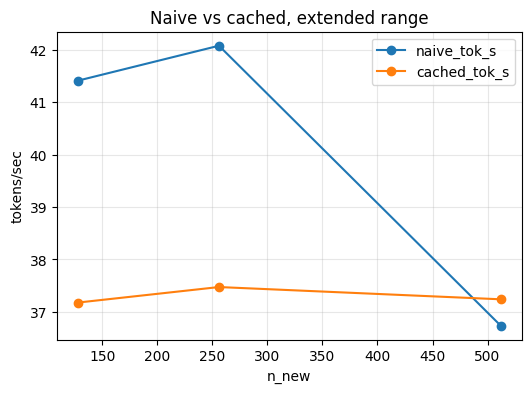

In [18]:
line(long_df, "n_new", ["naive_tok_s", "cached_tok_s"],
     "Naive vs cached, extended range", "tokens/sec", zero=False, save="stage1_2_crossover")

### 7.2 Crossover by interpolation

Treat `speedup_x` as a piecewise-linear curve and find where it crosses 1.0, once on a linear x-axis and once on a log2 x-axis. The two disagree slightly, and that gap shows how sensitive the answer is to how you model the axis (throughput curves are usually read on a log axis, so the choice matters in a write-up).

crossover (linear interp): n_new ≈ 483
crossover (log2 interp):   n_new ≈ 474


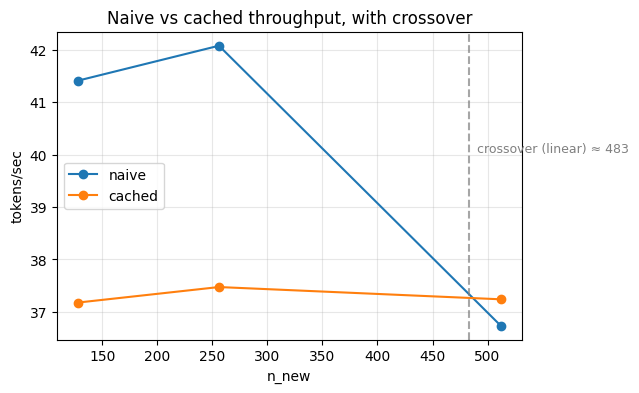

In [19]:
def show(v):
    return f"{v:.0f}" if v is not None else "none in the measured range"   # faster GPUs may not cross

crossover_linear = find_crossover(long_df, "n_new", "speedup_x", target=1.0, log_x=False)
crossover_log = find_crossover(long_df, "n_new", "speedup_x", target=1.0, log_x=True)
print(f"crossover (linear interp): n_new ≈ {show(crossover_linear)}")
print(f"crossover (log2 interp):   n_new ≈ {show(crossover_log)}")

crossover_plot(long_df, "Naive vs cached throughput, with crossover",
               cross=crossover_linear, cross_label="crossover (linear)", fmt="o-",
               save="stage1_2_crossover_annotated")

### 7.3 Crossover by curve fit

Fit `naive_s(n_new)` with a degree-2 polynomial and `cached_s(n_new)` with a degree-1 polynomial, then solve `naive(x) = cached(x)` with `scipy.optimize.brentq`. Plotting `x / poly(x)` turns the fitted times back into tokens/sec so they overlay the measurements.

crossover (curve fit): n_new ≈ 488


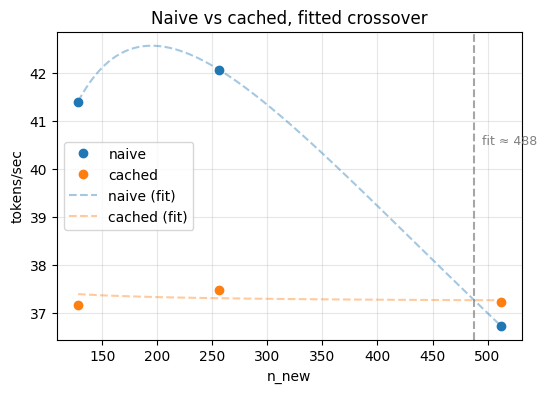

In [20]:
# naive time is roughly quadratic (context grows every step); cached is roughly linear
naive_poly = np.poly1d(np.polyfit(long_df["n_new"], long_df["naive_s"], deg=2))
cached_poly = np.poly1d(np.polyfit(long_df["n_new"], long_df["cached_s"], deg=1))

try:
    crossover_fit = brentq(lambda x: naive_poly(x) - cached_poly(x), 128, 512)
except ValueError:   # no sign change: the curves do not cross in this range
    crossover_fit = None
print(f"crossover (curve fit): n_new ≈ {show(crossover_fit)}")

crossover_plot(long_df, "Naive vs cached, fitted crossover", cross=crossover_fit, cross_label="fit",
               fits=(naive_poly, cached_poly), fmt="o", save="stage1_2_crossover_quadratic_fit")

### 7.4 Dense probe near the crossover

A second sweep at `n_new_probe`, right around the predicted crossover. The probe is the direct measurement, so trust it over the sweep-based estimates when they disagree. The fitted curves should pass close to the probe points. Even when they do, the crossing can move by tens of tokens, because the two throughput curves are nearly parallel there. Set `QUICK = True` in the setup cell to skip this section (about 4 minutes).

  n_new=300: naive 40.9 tok/s, cached 37.0 tok/s, speedup 0.906x [46.2s]
  n_new=340: naive 39.7 tok/s, cached 37.0 tok/s, speedup 0.932x [53.0s]
  n_new=380: naive 38.9 tok/s, cached 36.9 tok/s, speedup 0.947x [60.0s]
  n_new=400: naive 38.1 tok/s, cached 37.2 tok/s, speedup 0.976x [63.5s]
  n_new=440: naive 36.5 tok/s, cached 37.2 tok/s, speedup 1.019x [71.3s]


,n_new,naive_tok_s,cached_tok_s,speedup_x
0,300,40.868,37.009,0.906
1,340,39.732,37.029,0.932
2,380,38.916,36.859,0.947
3,400,38.118,37.218,0.976
4,440,36.546,37.237,1.019


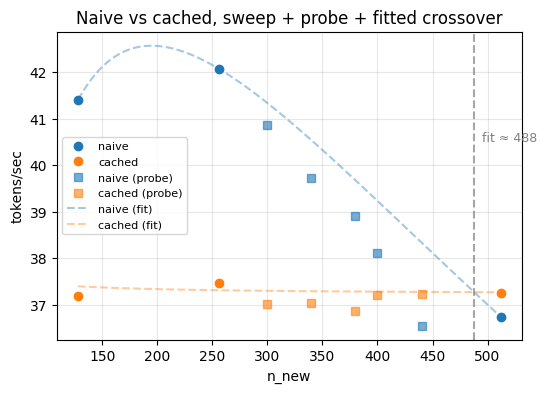

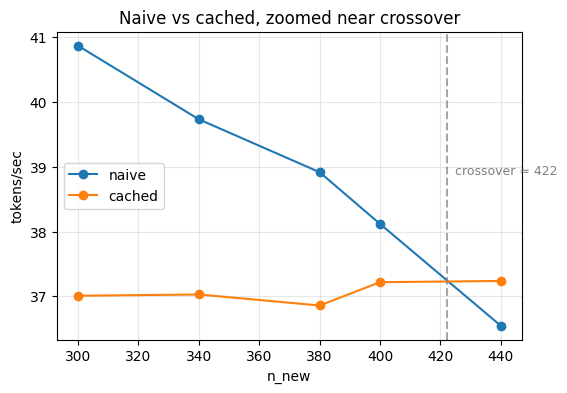

measured crossover (probe, interpolated): n_new ≈ 422


In [21]:
PROBE_COLS = ["n_new", "naive_tok_s", "cached_tok_s", "speedup_x"]
N_NEW_PROBE = [300, 340, 380, 400, 440] 

probe_df, exact_crossover = None, None
if not QUICK:
    probe_df = sweep_lengths(model, bench_ids, N_NEW_PROBE, naive_iters=2, cached_runs=2)
    display(probe_df[PROBE_COLS].round(3))

    crossover_plot(long_df, "Naive vs cached, sweep + probe + fitted crossover", cross=crossover_fit,
                   cross_label="fit", fits=(naive_poly, cached_poly), probe=probe_df, fmt="o",
                   save="stage1_2_crossover_sweep_probe_fit")

    exact_crossover = find_crossover(probe_df, "n_new", "speedup_x", target=1.0, log_x=False)
    crossover_plot(probe_df, "Naive vs cached, zoomed near crossover", cross=exact_crossover,
                   fmt="o-", save="stage1_2_crossover_probe")
    print(f"measured crossover (probe, interpolated): n_new ≈ {show(exact_crossover)}")
else:
    print("QUICK = True: probe sweep skipped")

**Takeaway.** The cache starts to win at a few hundred new tokens, but the exact crossing is soft. The sweep estimates (two interpolations and the fit) use only a few widely spaced lengths, so they are coarse. The dense probe measures the crossing directly, and it can land away from them. The speedup curve is shallow near the crossing, so a few percent of noise moves the crossing by tens of tokens, and it moves a lot between reruns. Quote a range, prefer the probe, and expect the cache's lead just past the crossing to be small. Beyond it, the naive path's growing recompute cost finally exceeds the cached path's constant per-token cost.

**Exercise.** Repeat the sweep with `PROMPT_LEN = 512`. Does the crossover move left or right? (Hint: a longer prompt makes every naive step more expensive.)

---
## 8. Prefill scaling: TTFT & ITL vs prompt length

Everything so far used one prompt length (128), so it could not distinguish "TTFT grows with the prompt" from "TTFT is constant". Here we vary the prompt over `[32, 128, 512, 2048]` with a fixed 16-token generation. We also record decode ITL (inter-token latency) at each prompt length, to test whether a longer context slows decode.

Derived columns: `prefill_tok_s` (prompt tokens processed per second) and `kv_mib` (cache footprint at that prompt length, for comparison with the roofline KV bytes).

**Concept.** Prefill processes many tokens per weight read, so it should be far more compute-heavy than decode. If the GPU were saturated, TTFT would grow in proportion to the prompt and `prefill_tok_s` would level off.

> **Predict:** at which prompt length does TTFT start to grow?

In [22]:
PROMPT_LENS = [32, 128, 512, 2048]
prompt_df = sweep_prompts(model, PROMPT_LENS, bpt)
prompt_df.round(3)

,prompt_len,ttft_ms,itl_p50_ms,ttft_s,prefill_tok_s,kv_mib
0,32,27.213,26.886,0.027,1175.893,0.375
1,128,26.900,26.735,0.027,4758.322,1.500
2,512,26.745,26.676,0.027,19144.076,6.000
3,2048,117.953,26.894,0.118,17362.809,24.000


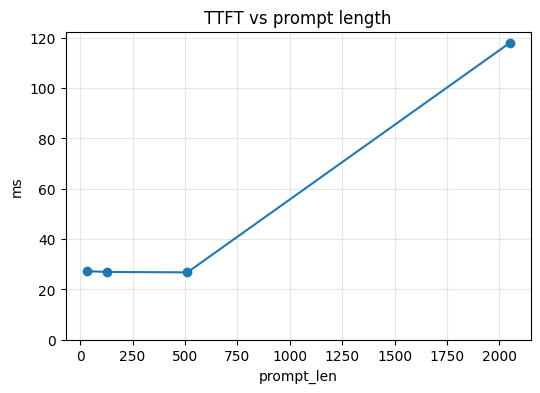

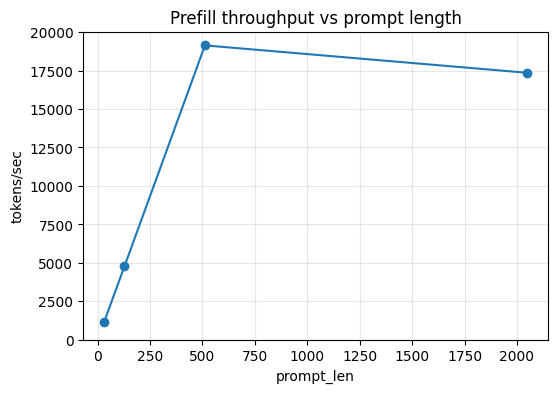

In [23]:
line(prompt_df, "prompt_len", ["ttft_ms"],
     "TTFT vs prompt length", "ms", save="stage1_2_ttft_scaling")
line(prompt_df, "prompt_len", ["prefill_tok_s"],
     "Prefill throughput vs prompt length", "tokens/sec", save="stage1_2_prefill_throughput")

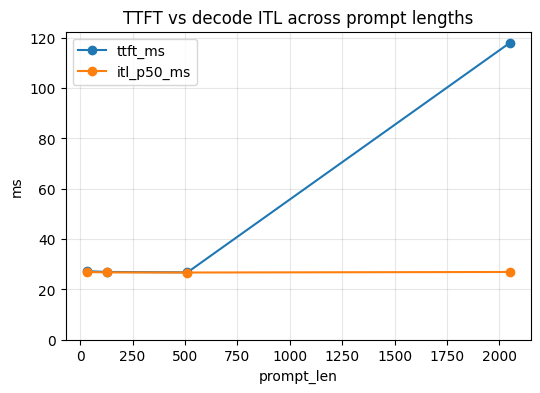

In [24]:
line(prompt_df, "prompt_len", ["ttft_ms", "itl_p50_ms"],
     "TTFT vs decode ITL across prompt lengths", "ms",
     save="stage1_2_ttft_itl_vs_prompt")

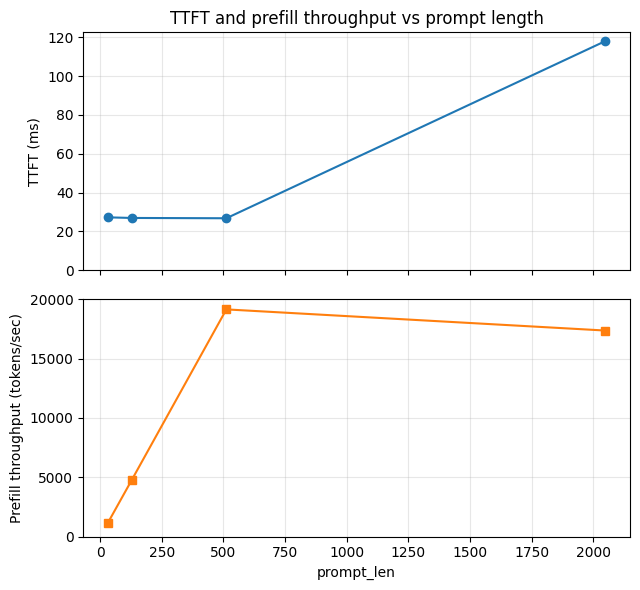

In [25]:
line_stacked(prompt_df, "prompt_len", "ttft_ms", "prefill_tok_s",
             "TTFT and prefill throughput vs prompt length",
             "TTFT (ms)", "Prefill throughput (tokens/sec)",
             save="stage1_2_ttft_and_throughput")

**Takeaway.** For prompts up to a few hundred tokens TTFT is flat, and about the same as one decode step: the prefill is *launch-bound* like decode, so a short and a mid-sized prompt cost about the same and `prefill_tok_s` rises almost in proportion to the prompt. Only at the longest prompt does real compute show up: TTFT jumps and `prefill_tok_s` falls back. That is a modest fraction of the spec peak in useful work (prefill rate times decode FLOPs per token, an approximation), so long prefill is compute-heavy rather than launch-bound. The knee lies between the two longest prompts. Batching many short prompts together is therefore nearly free, which is the motivation for Stages 3 and 4.

Decode ITL stays flat at every prompt length, because ITL is set by per-step weight reads and launch overhead. A longer prompt only adds KV bytes (24 MiB at 2048 tokens, about 2.5% of the weights).

---
## 9. Closing the gap: `torch.compile` on decode

**Hypothesis.** Section 6 showed decode far below the bandwidth ceiling, pointing at Python and kernel-launch overhead rather than bandwidth. `torch.compile(mode="reduce-overhead")` fuses ops and replays them with CUDA graphs, which removes most of that overhead. We compile only the single-token decode step (`decode_fn`); prefill stays eager.

**Fair comparison.** Eager and compiled are both measured the same way: `bench_cached` at 128 new tokens, tokens/sec from the p50 inter-token latency. The one-time compile cost is timed separately.

> Restart the kernel first if you ran other benchmarks in this session. `torch.compile` caches by shape, and a dirty session can cause misleading recompilation stalls.

In [26]:
import torch._dynamo
import torch._inductor.config as inductor_config

torch._dynamo.reset()
gc.collect()
torch.cuda.empty_cache()

# Silence the cudagraph skip/recompile chatter (informational, not errors)
logging.getLogger("torch._inductor").setLevel(logging.ERROR)
logging.getLogger("torch._dynamo").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*cudagraph.*")
inductor_config.triton.cudagraph_dynamic_shape_warn_limit = None

compiled_forward = torch.compile(model.forward, mode="reduce-overhead")
generate_compiled = partial(generate_cached, decode_fn=compiled_forward)

# The first call triggers compilation; time it separately since it is a one-time cost
warmup_t = sync_time(lambda: generate_compiled(model, bench_ids, 32), warmup=0, iters=1)
compiled = bench_cached(generate_compiled, model, bench_ids, 128)
compiled_tok_s = 1000 / compiled["itl_p50_ms"]

print(f"compile warm-up: {warmup_t:.2f}s (one-time)")
print(f"compiled decode: {compiled_tok_s:.0f} tok/s vs eager {decode_tok_s:.0f} tok/s "
      f"({pct_of(compiled_tok_s, ceil_meas):.0f}% of measured ceiling, eager {pct_of(decode_tok_s, ceil_meas):.0f}%)")

compile warm-up: 87.96s (one-time)
compiled decode: 76 tok/s vs eager 38 tok/s (31% of measured ceiling, eager 15%)


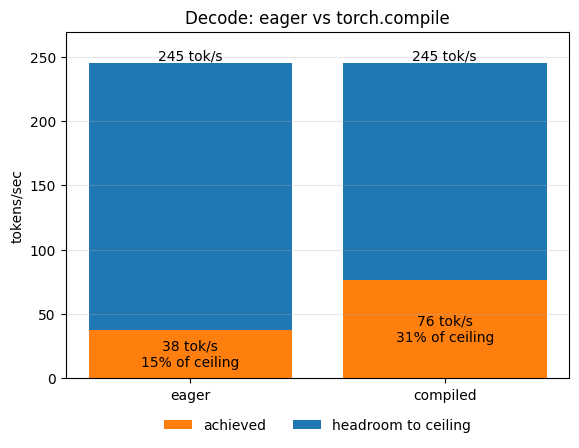

In [27]:
# bar(["eager", "compiled"], [decode_tok_s, compiled_tok_s],
#     "Decode: eager vs torch.compile", "tokens/sec", save="stage1_2_compile")
ceiling_bar({"eager": decode_tok_s, "compiled": compiled_tok_s}, ceil_meas,
            "Decode: eager vs torch.compile", "tokens/sec",
            achieved_label="achieved", save="stage1_2_compile")

**Takeaway.** Compiling the decode step roughly doubles achieved throughput, confirming the overhead hypothesis, but it is still well below the ceiling. The remaining gap is more launch overhead, inefficient kernels and extra data movement (for example the `repeat_interleave` copy of KV heads).

**Exercises.**
1. Replace `repeat_interleave` in `model.py` with `enable_gqa=True` in `F.scaled_dot_product_attention` (recent PyTorch) and re-measure ITL.
2. Capture the decode step in a CUDA graph by hand (`torch.cuda.CUDAGraph`) and compare with `mode="reduce-overhead"`.

---
## 10. The roofline chart

**Goal:** place decode on the classic roofline picture.

- x-axis: **arithmetic intensity** = FLOPs / bytes moved.
- y-axis: achieved **TFLOP/s**.
- Sloped lines are the **memory roofs**: `performance = intensity x bandwidth`. The flat line is the GPU's **FP16 compute roof**. They meet at the **ridge point**.
- Points to the left of the ridge are memory-bound; to the right, compute-bound.

FLOPs per decode token are estimated from the linear layers plus the QK^T and AV attention work at the benchmark context. Bytes per token are `weight bytes + KV bytes`, the same model as the ceiling in section 6, so the two views are directly comparable. This is an analytical upper-bound model, not a full accounting of every byte and operation the GPU runs.

The FP16 compute roof is the tensor-core *peak* from the spec sheet, which real kernels do not sustain. It only sets the height of the flat line.

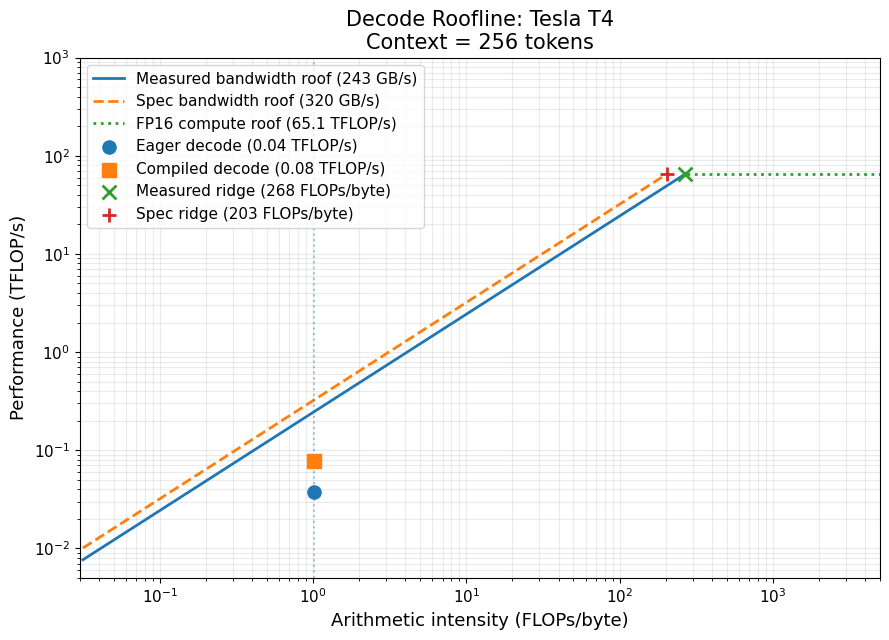

Roofline summary
----------------
GPU:                    Tesla T4
Context length:         256
Decode FLOPs/token:     1.01 GFLOPs
Decode bytes/token:     945.29 MiB
Arithmetic intensity:   1.02 FLOPs/byte
Measured bandwidth:     242.8 GB/s
Spec bandwidth:         320 GB/s
Measured BW roof:       0.247 TFLOP/s
Spec BW roof:           0.326 TFLOP/s
Compute roof:           65.1 TFLOP/s
Eager achieved:         0.0380 TFLOP/s
Compiled achieved:      0.0771 TFLOP/s
Measured ridge:         268.1 FLOPs/byte
Spec ridge:             203.4 FLOPs/byte
AI / measured ridge AI: 0.380%
AI / spec ridge AI:     0.501%


In [28]:
pt = roofline.roofline_point(model, ctx, w_bytes, kv_bytes, gpu_name, spec_bw, meas_bw,
                             eager_tok_s=decode_tok_s, compiled_tok_s=compiled_tok_s)
roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, save="stage1_2_roofline_model")
roofline.print_roofline_summary(pt, gpu_name, ctx, spec_bw, meas_bw)

**Takeaway.** Decode sits at about one FLOP per byte, a tiny fraction of the measured ridge point (a few hundred FLOPs per byte), so it is deep in the memory-bound region. Adding raw compute would not help batch-1 decode; what helps is reading fewer bytes per token or doing more work per byte read. **Batching** many sequences shares each weight read across all of them and raises arithmetic intensity, which is exactly what Stages 3 and 4 do.

Both operating points still sit below the bandwidth roof at this intensity, with compiled decode closer to it than eager. So this implementation has headroom before bandwidth itself is the limit. Next targets: less launch overhead (CUDA graphs), no wasted data movement (`enable_gqa`), and more efficient GQA handling.

---
## 11. Save results

`results/stage1_2.json` holds everything needed to re-plot without re-running:

- `env`: GPU, library versions, model id and revision, `max_pos`
- `prompt_len` and `table`: the naive vs cached table (section 5)
- `roofline`: bandwidths, byte and FLOP counts, ceilings, achieved rates, ridge points
- `extended`: the crossover sweeps (`n_new_sweep`, `probe_n_new_sweep`), `prompt_len_sweep`, the four crossover estimates, compiled decode tok/s and compile warm-up

Final published numbers should come from one consistent environment.

In [29]:
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "prompt_len": PROMPT_LEN,
    "table": merged.round(4).to_dict(orient="records"),

    "roofline": {
        "context_len": ctx,
        "spec_bw_gbps": spec_bw,
        "measured_bw_gbps": meas_bw,
        "weight_bytes": w_bytes,
        "kv_bytes_per_token": bpt,
        "kv_bytes_at_context": kv_bytes,
        "decode_bytes_per_token": pt["decode_bytes"],
        "decode_flops_per_token": pt["decode_flops"],
        "arithmetic_intensity_flops_per_byte": pt["arithmetic_intensity"],
        "ceiling_tok_s_measured": ceil_meas,
        "ceiling_tok_s_spec": ceil_spec,
        "achieved_tok_s": decode_tok_s,
        "eager_tflops": pt["eager_tflops"],
        "compiled_tflops": pt["compiled_tflops"],
        "compute_peak_tflops": pt["compute_peak_tflops"],
        "measured_ridge_ai": pt["ridge_measured"],
        "spec_ridge_ai": pt["ridge_spec"],
        "ai_over_measured_ridge": pt["ai_over_measured_ridge"],
        "ai_over_spec_ridge": pt["ai_over_spec_ridge"],
        "eager_pct_measured_ceiling": pct_of(decode_tok_s, ceil_meas),
        "compiled_pct_measured_ceiling": pct_of(compiled_tok_s, ceil_meas),
        "compiled_vs_eager_x": compiled_tok_s / decode_tok_s,
    },

    "extended": {
        "n_new_sweep": long_df[TABLE_COLS].round(4).to_dict(orient="records"),
        "probe_n_new_sweep": probe_df[PROBE_COLS].round(4).to_dict(orient="records") if probe_df is not None else None,
        "prompt_len_sweep": prompt_df.round(4).to_dict(orient="records"),

        "crossover_linear": crossover_linear,
        "crossover_log2": crossover_log,
        "crossover_curve_fit": crossover_fit,
        "crossover_targeted_probe": exact_crossover,

        "compiled_decode_tok_s": compiled_tok_s,
        "compile_warmup_s": warmup_t,
    },
}
save_results("results/stage1_2.json", out)

saved results/stage1_2.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it, right next to the data behind it. This cell lists them and fails if any expected figure is missing (for example after a `QUICK` run, which skips the two probe figures).

In [30]:
FIGURES = {
    "stage1_2_throughput.png": "Naive vs cached tok/s, N_NEW_LIST (section 6)",
    "stage1_2_latency.png": "TTFT vs ITL p50: the prefill vs decode split (section 6)",
    "stage1_2_roofline.png": "Achieved decode tok/s vs measured and spec ceilings (section 6)",
    "stage1_2_crossover.png": "Naive vs cached tok/s, N_NEW_LONG (section 7.1)",
    "stage1_2_crossover_annotated.png": "Same, with the interpolated crossover (section 7.2)",
    "stage1_2_crossover_quadratic_fit.png": "Quadratic-naive and linear-cached fits (section 7.3)",
    "stage1_2_crossover_sweep_probe_fit.png": "Fits overlaid with sweep and probe points (section 7.4, skipped if QUICK)",
    "stage1_2_crossover_probe.png": "Probe window alone, crossover marked (section 7.4, skipped if QUICK)",
    "stage1_2_ttft_scaling.png": "TTFT vs prompt length (section 8)",
    "stage1_2_prefill_throughput.png": "Prefill tok/s vs prompt length (section 8)",
    "stage1_2_ttft_itl_vs_prompt.png": "TTFT and decode ITL p50 vs prompt length (section 8)",
    "stage1_2_ttft_and_throughput.png": "TTFT and prefill throughput vs prompt length (section 8)",
    "stage1_2_compile.png": "Eager vs torch.compile decode tok/s (section 9)",
    "stage1_2_roofline_model.png": "Decode roofline: TFLOP/s vs arithmetic intensity (section 10)",
}
optional = {"stage1_2_crossover_sweep_probe_fit.png", "stage1_2_crossover_probe.png"} if QUICK else set()
missing = [f for f in FIGURES if f not in optional and not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage1_2_throughput.png,"Naive vs cached tok/s, N_NEW_LIST (section 6)"
1,stage1_2_latency.png,TTFT vs ITL p50: the prefill vs decode split (...
2,stage1_2_roofline.png,Achieved decode tok/s vs measured and spec cei...
3,stage1_2_crossover.png,"Naive vs cached tok/s, N_NEW_LONG (section 7.1)"
4,stage1_2_crossover_annotated.png,"Same, with the interpolated crossover (section..."
5,stage1_2_crossover_quadratic_fit.png,Quadratic-naive and linear-cached fits (sectio...
6,stage1_2_crossover_sweep_probe_fit.png,Fits overlaid with sweep and probe points (sec...
7,stage1_2_crossover_probe.png,"Probe window alone, crossover marked (section ..."
8,stage1_2_ttft_scaling.png,TTFT vs prompt length (section 8)
9,stage1_2_prefill_throughput.png,Prefill tok/s vs prompt length (section 8)


---
## 12. Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. So this notebook, once a later stage has been published, pushes results only and cannot overwrite newer code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [31]:
PUSH = True                                           # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 1-2: naive baseline + KV cache"   # the only other line that differs between notebooks
FORCE_CODE = False                                    # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 510, done.        
remote: Counting objects: 100% (222/222), done.        
remote: Compressing objects: 100% (175/175), done.        
remote: Total 510 (delta 91), reused 152 (delta 43), pack-reused 288 (from 1)        
Receiving objects: 100% (510/510), 11.30 MiB | 21.55 MiB/s, done.
Resolving deltas: 100% (219/219), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 2, repo code stage 3: publishing results only (the repo code is newer)
[main 930a36f] Stage 1-2: naive baseline + KV cache
 15 files changed, 182 insertions(+), 182 deletions(-)
Enumerating objects: 34, done.
Counting objects: 100% (34/34), done.
Delta compression using up to 4 threads
Compressing objects: 100% (18/18), done.
Writing objects: 100% (18/18), 713.50 KiB | 16.22 MiB/s, done.
Total 18 (delta 3), reused 0 (delta 0), pack-reused 0
To https://github.com/chizkidd/minivllm.git
   ca

---
## 13. Summary

In [32]:
r = out["roofline"]
print(f"Naive vs cached (prompt {PROMPT_LEN}, n_new {N_NEW_LIST[0]}..{N_NEW_LIST[-1]}): "
      f"speedup {merged['speedup_x'].min():.2f}x to {merged['speedup_x'].max():.2f}x")
print(f"Cache starts to win at n_new ≈ {show(exact_crossover or crossover_fit)}")
print(f"TTFT {prompt_df['ttft_ms'].iloc[0]:.0f} ms at {PROMPT_LENS[0]} tokens -> "
      f"{prompt_df['ttft_ms'].iloc[-1]:.0f} ms at {PROMPT_LENS[-1]} tokens; decode ITL p50 {cached_df['itl_p50_ms'].iloc[-1]:.1f} ms")
print(f"Decode vs measured bandwidth ceiling: eager {r['eager_pct_measured_ceiling']:.0f}%, "
      f"compiled {r['compiled_pct_measured_ceiling']:.0f}% ({r['compiled_vs_eager_x']:.1f}x)")
print(f"Arithmetic intensity {pt['arithmetic_intensity']:.2f} FLOPs/byte: memory-bound")

Naive vs cached (prompt 128, n_new 16..128): speedup 0.88x to 0.92x
Cache starts to win at n_new ≈ 422
TTFT 27 ms at 32 tokens -> 118 ms at 2048 tokens; decode ITL p50 26.6 ms
Decode vs measured bandwidth ceiling: eager 15%, compiled 31% (2.0x)
Arithmetic intensity 1.02 FLOPs/byte: memory-bound


### What we learned

- **Correctness first.** Parity against Hugging Face gates every benchmark.
- **The KV cache is not automatically faster.** At batch 1 on a small model both paths are launch-bound, so the cache is slightly slower at short outputs and only wins once naive recomputation grows large enough. The crossover is at a few hundred new tokens, its exact position moves between runs, and the cache's advantage grows only slowly beyond it.
- **Prefill and decode behave differently.** Decode is a flat per-token cost set by memory traffic and overhead, whatever the prompt length. Prefill is just as flat for short prompts, up to about 512 tokens, and only grows once compute starts to matter (it has clearly grown by 2048).
- **Decode is memory-bound in theory and overhead-bound in practice.** Eager decode reaches only a small fraction of the bandwidth ceiling. `torch.compile` roughly doubles it, which still leaves a large gap.
- **Batching is the lever.** With about 1 FLOP per byte, the only way to use the hardware is to share each weight read across many sequences.

### Next: Stage 3, static batching

The next notebook (`02_static_batching`) serves several sequences at once. That needs left padding, an attention mask and per-sequence RoPE positions, which changes both `MiniQwen.forward` and `KVCache`. It measures the padding waste and the latency penalty for short requests, which sets up Stage 4 continuous batching, the core insight of modern serving.

### References

- Qwen2.5 technical report: https://arxiv.org/abs/2412.15115
- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785